# d5 · Quantization: 8, 4 and 2 bits

Every model on the d4 frontier is quantized: its weights are stored with *b* bits instead of 32, plus one fp32
scale per output channel (d1).

| method | what happens | cost |
|---|---|---|
| **post-training (PTQ)** | round the trained weights to the grid | none, seconds |
| **quantization-aware training (QAT)** | fine-tune with the rounding in the forward pass (straight-through gradient), so the weights settle where rounding hurts least | 20 epochs at lr 0.003 |
| **real int8 (PyTorch FX, x86)** | weights *and* activations in int8, run by PyTorch's quantized CPU kernels | calibration on 1,280 train images |

Bit widths: **8** (256 levels), **4** (15 levels), **2** (3 levels: −1, 0, +1 times a scale, i.e. ternary).
QAT keeps the pruning pattern of a pruned model (its zeros stay zero) and trains with the teacher if the model
was distilled. Sub-8-bit is simulated: the accuracy is exactly that of a model whose weights take only those
values, but no PyTorch kernel runs 4- or 2-bit weights, so there is no latency for them.

Real int8 also checks the simulation: its accuracy should match simulated 8-bit PTQ closely (it additionally
quantizes the activations).

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib import compress as C, dreport as R
from lib.train import RESULTS, Config
from lib.data import ARTIFACTS
FRONT = [f for f in json.loads((ARTIFACTS / "d4_frontier.json").read_text()) if f["run"]]
def src_runs(ref):
    exp, n = ref.split("/")
    return [json.loads((RESULTS / exp / f"{n}_s{s}.json").read_text()) for s in R.SEEDS3]
def qat_cfg(ref, bits):
    exp, n = ref.split("/")
    c = src_runs(ref)[0]["config"]
    c = Config(**{k: tuple(v) if isinstance(v, list) else v for k, v in c.items()})
    keep = {k: c.extra[k] for k in ["kd"] if k in c.extra}
    sp = src_runs(ref)[0]["size"]["sparsity"]
    if sp > 0.01: keep["prune"] = {"sparsity": round(sp, 4), "ramp": 0}   # hold the existing zeros
    return replace(c, exp="d5", name=f"{n}_qat{bits}", lr=0.003, epochs=20, patience=10, extra={**keep, "wbits": bits})
print(len(FRONT), "frontier models from d4:"); display(pd.DataFrame(FRONT))

12 frontier models from d4:


,label,run,bytes,bal_acc,sparsity
0,dwsep_k5_w4 pruned 95 %,d4/dwsep_k5_w4_dist_prune95,959,0.2500,0.9499
1,dwsep_k5_w4 pruned 90 %,d4/dwsep_k5_w4_dist_prune90,1303,0.3477,0.8998
2,dwsep_k5_w4 pruned 75 %,d4/dwsep_k5_w4_dist_prune75,2331,0.5651,0.7500
3,dwsep_k5_w2 (labels only),d2/dwsep_k5_w2,2952,0.7946,0.0000
4,dwsep_k5_w4 pruned 50 %,d4/dwsep_k5_w4_dist_prune50,4047,0.8580,0.5000
5,dwsep_k5_w4 (distilled),d3/dwsep_k5_w4_kdT4a0.5,7264,0.8685,0.0000
6,dwsep_k3_w8 (labels only),d2/dwsep_k3_w8,15408,0.8906,0.0000
7,dwsep_k5_w8 (labels only),d2/dwsep_k5_w8,20016,0.9158,0.0000
8,dwsep_k3_w16 (labels only),d2/dwsep_k3_w16,52816,0.9484,0.0000
9,dwsep_k5_w32 pruned 75 %,d4/dwsep_k5_w32_labe_prune75,61876,0.9598,0.7500


## 1. Post-training and quantization-aware, every frontier model

In [2]:
Q = {}
for f in FRONT:
    exp, n = f["run"].split("/")
    Q[(f["label"], "fp32")] = src_runs(f["run"])
    for b in [8, 4, 2]:
        Q[(f["label"], f"PTQ {b}-bit")] = [R.ptq(exp, f"{n}_s{s}", "d5", b) for s in R.SEEDS3]
    for b in [8, 4, 2]:
        base = qat_cfg(f["run"], b)
        Q[(f["label"], f"QAT {b}-bit")] = [R.run(R.with_src(base, f["run"], "init", s, **base.extra)) for s in R.SEEDS3]
    Q[(f["label"], "real int8")] = [R.ptq(exp, f"{n}_s{s}", "d5", "int8") for s in R.SEEDS3]
TQ = R.table({f"{m} | {q}": v for (m, q), v in Q.items()})
TQ["model"] = [m for (m, q) in Q]; TQ["quant"] = [q for (m, q) in Q]
P = TQ.pivot(index="model", columns="quant", values="bal_acc").astype(float)
P = P[["fp32", "PTQ 8-bit", "QAT 8-bit", "real int8", "PTQ 4-bit", "QAT 4-bit", "PTQ 2-bit", "QAT 2-bit"]]
P.insert(0, "fp32 kB", TQ[TQ.quant == "fp32"].set_index("model").kB.astype(float))
display(P.sort_values("fp32 kB").round(4))

C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


... (27 outputs left out)

C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


C:\Users\vikto\Documents\DNN-lok\.venv\Lib\site-packages\torch\ao\quantization\observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(


quant,fp32 kB,fp32,PTQ 8-bit,QAT 8-bit,real int8,PTQ 4-bit,QAT 4-bit,PTQ 2-bit,QAT 2-bit
model,,,,,,,,,
dwsep_k5_w4 pruned 95 %,0.9365,0.2500,0.2500,0.2500,0.2500,0.2500,0.2500,0.2500,0.2500
dwsep_k5_w4 pruned 90 %,1.2725,0.3477,0.3489,0.3574,0.3269,0.3458,0.3581,0.2633,0.3505
dwsep_k5_w4 pruned 75 %,2.2764,0.5651,0.5652,0.5838,0.5310,0.5594,0.7394,0.2946,0.5427
dwsep_k5_w2 (labels only),2.8828,0.7946,0.7917,0.8034,0.7707,0.6147,0.7860,0.2500,0.5119
dwsep_k5_w4 pruned 50 %,3.9521,0.8580,0.8570,0.8607,0.8534,0.6788,0.8576,0.2657,0.7151
dwsep_k5_w4 (distilled),7.0938,0.8685,0.8674,0.8839,0.8643,0.7155,0.8612,0.3214,0.5896
dwsep_k3_w8 (labels only),15.0469,0.8906,0.8882,0.9089,0.8859,0.7719,0.8922,0.2500,0.6532
dwsep_k5_w8 (labels only),19.5469,0.9158,0.9188,0.9330,0.9083,0.7777,0.9244,0.2474,0.6992
dwsep_k3_w16 (labels only),51.5781,0.9484,0.9486,0.9539,0.9469,0.8147,0.9506,0.2494,0.7374


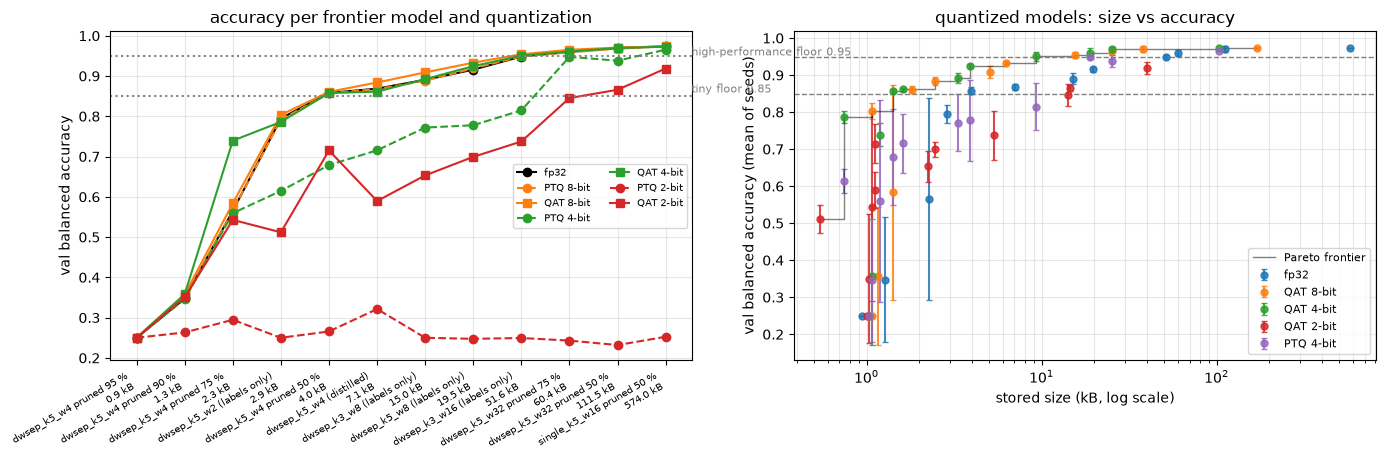

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
order = P.sort_values("fp32 kB").index
for i, q in enumerate(["fp32", "PTQ 8-bit", "QAT 8-bit", "PTQ 4-bit", "QAT 4-bit", "PTQ 2-bit", "QAT 2-bit"]):
    ax[0].plot(range(len(order)), P.loc[order, q], marker="o" if "PTQ" in q or q == "fp32" else "s",
               ls="--" if "PTQ" in q else "-", label=q, color={"fp32": "k"}.get(q, f"C{(i + 1) // 2}"))
ax[0].set_xticks(range(len(order)), [f"{m[:28]}\n{kb:.1f} kB" for m, kb in zip(order, P.loc[order, "fp32 kB"])], rotation=30, ha="right", fontsize=7)
ax[0].set(ylabel="val balanced accuracy", title="accuracy per frontier model and quantization"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=7, ncol=2)
for fl in R.FLOORS.values(): ax[0].axhline(fl, ls=":", color="grey")
R.tradeoff_plot({q: TQ[TQ.quant == q] for q in ["fp32", "QAT 8-bit", "QAT 4-bit", "QAT 2-bit", "PTQ 4-bit"]},
                "quantized models: size vs accuracy", ax=ax[1])
plt.tight_layout(); plt.show()

_TODO quant_

## 2. Real int8 vs simulated 8-bit, and latency

In [4]:
rows = []
for f in FRONT:
    ri = Q[(f["label"], "real int8")]
    rows.append({"model": f["label"], "simulated 8-bit PTQ": np.mean([r["val"]["bal_acc"] for r in Q[(f["label"], "PTQ 8-bit")]]),
                 "real int8": np.mean([r["val"]["bal_acc"] for r in ri]),
                 "analytic 8-bit kB": np.mean([r["size"]["bytes"] for r in ri]) / 1024,
                 "torch.save int8 kB": np.mean([r["size"]["serialized_bytes"] for r in ri]) / 1024,
                 "fp32 ms": np.mean([r["latency"]["fp32_ms"] for r in ri]), "int8 ms": np.mean([r["latency"]["int8_ms"] for r in ri])})
RI = pd.DataFrame(rows).set_index("model"); RI["int8 - sim (pp)"] = (RI["real int8"] - RI["simulated 8-bit PTQ"]) * 100
display(RI.round(4))

,simulated 8-bit PTQ,real int8,analytic 8-bit kB,torch.save int8 kB,fp32 ms,int8 ms,int8 - sim (pp)
model,,,,,,,
dwsep_k5_w4 pruned 95 %,0.2500,0.2500,1.0752,22.5840,1.1040,5.3770,0.0000
dwsep_k5_w4 pruned 90 %,0.3489,0.3269,1.1592,22.5840,1.0826,5.3980,-2.1954
dwsep_k5_w4 pruned 75 %,0.5652,0.5310,1.4102,22.5840,1.0812,5.3769,-3.4173
dwsep_k5_w2 (labels only),0.7917,0.7707,1.0762,20.7090,0.9731,3.7037,-2.0967
dwsep_k5_w4 pruned 50 %,0.8570,0.8534,1.8291,22.5840,1.0793,5.3791,-0.3613
dwsep_k5_w4 (distilled),0.8674,0.8643,2.4570,22.5840,1.0734,5.3763,-0.3072
dwsep_k3_w8 (labels only),0.8882,0.8859,5.1016,26.7090,1.1570,2.2019,-0.2300
dwsep_k5_w8 (labels only),0.9188,0.9083,6.2266,27.8340,1.2780,2.6521,-1.0498
dwsep_k3_w16 (labels only),0.9486,0.9469,15.5469,39.3965,1.5786,2.8224,-0.1662


_TODO int8_

## 3. Decision and frontier after quantization

In [5]:
best_q = {}
for f in FRONT:   # per model and bit width: QAT or PTQ, highest mean
    for b in [8, 4, 2]:
        pt, qa = TQ.loc[f"{f['label']} | PTQ {b}-bit"], TQ.loc[f"{f['label']} | QAT {b}-bit"]
        best_q[(f["label"], b)] = "QAT" if float(qa.bal_acc) > float(pt.bal_acc) else "PTQ"
print("QAT better than PTQ in", sum(v == "QAT" for v in best_q.values()), "of", len(best_q), "model/bit-width pairs")
keep = {k: v for (m, q), v in Q.items() for k in [f"{m} | {q}"] if q != "real int8"}
TK = R.table(keep); F5 = R.pareto(TK)
display(F5[["kB", "x smaller than teacher", "sparsity", "wbits", "bal_acc", "sd"]].round(4))
def ref_of(m, q):
    f = next(x for x in FRONT if x["label"] == m); exp, n = f["run"].split("/")
    if q == "fp32": return f["run"]
    b = q.split()[1].split("-")[0]
    return f"d5/{n}_qat{b}" if q.startswith("QAT") else f"d5/{n}_ptq{b}"
front = [{"label": k, "run": ref_of(*k.split(" | ")), "bytes": int(F5.loc[k, "bytes"]), "bal_acc": float(F5.loc[k, "bal_acc"])} for k in F5.index]
_ = (ARTIFACTS / "d5_frontier.json").write_text(json.dumps(front, indent=1))

QAT better than PTQ in 32 of 36 model/bit-width pairs


,kB,x smaller than teacher,sparsity,wbits,bal_acc,sd
dwsep_k5_w2 (labels only) | PTQ 2-bit,0.5433,1988.2878,0.6827,2,0.2500,0.0000
dwsep_k5_w2 (labels only) | QAT 2-bit,0.5456,1981.1613,0.6691,2,0.5119,0.0383
dwsep_k5_w2 (labels only) | QAT 4-bit,0.7412,1456.5059,0.1365,4,0.7860,0.0162
dwsep_k5_w2 (labels only) | QAT 8-bit,1.0762,1003.1652,0.0112,8,0.8034,0.0210
dwsep_k5_w4 pruned 50 % | QAT 4-bit,1.4102,765.5734,0.5000,4,0.8576,0.0057
dwsep_k5_w4 (distilled) | QAT 4-bit,1.6191,666.7600,0.1329,4,0.8612,0.0036
dwsep_k5_w4 (distilled) | QAT 8-bit,2.4570,439.3831,0.0078,8,0.8839,0.0096
dwsep_k3_w8 (labels only) | QAT 4-bit,3.3164,325.5265,0.1216,4,0.8922,0.0127
dwsep_k5_w8 (labels only) | QAT 4-bit,3.8789,278.3202,0.1367,4,0.9244,0.0047
dwsep_k5_w8 (labels only) | QAT 8-bit,6.2266,173.3827,0.0078,8,0.9330,0.0043


_TODO decision_